# HW3 Part 1 — Tabular Q-Learning on CartPole
**Author:** Emily Echeverria

This notebook implements tabular Q-Learning on `CartPole-v1` after auditing the professor's MountainCar reference (see `professor_examples/021_Q_learning_MOUNTAIN_CAR_AUDIT.ipynb`). Three audit fixes are carried over:

1. `done = terminated or truncated` (the MountainCar example ignored truncation).
2. Bellman target uses `(1 - terminated)` mask so terminal states do not bootstrap.
3. Generalised `make_bins` / `discretize` for arbitrary obs dimensions; CartPole velocities are `±inf` in `observation_space`, so manual intervals are required.

Other deviations from the reference: per-episode ε decay (not per-100), 100-episode rolling window matching the env solved criterion, evaluation on **true** reward against the **195 / 100-episode** threshold from the PDF.

### Experiments
- **PDF §5 Q1** — bin sweep: coarse `[10,10,6,6]`, medium `[20,20,10,10]`, fine `[40,40,20,20]`.
- **PDF §5 Q2** — α ∈ {0.01, 0.1, 0.5} × γ ∈ {0.9, 0.95, 0.99} grid at the best bin config.
- **PDF §5 Q4** — ε schedule: per-episode decay (baseline), per-100-episode decay (mimic professor), constant ε.
- Final tuned run with 100-episode greedy evaluation.

Each configuration is run with **3 seeds**; we report mean ± std for episodes-to-solve and final 100-episode average reward.

In [1]:
import time
import numpy as np
import pandas as pd
import gymnasium as gym
import matplotlib.pyplot as plt

print('gymnasium', gym.__version__)
print('numpy', np.__version__)
np.set_printoptions(precision=3, suppress=True)

gymnasium 1.3.0
numpy 2.4.4


## Discretiser and Q-Learning agent

`make_bins` uses the cleaner pattern from the audit: `linspace(low, high, n+1)[1:-1]` gives `n-1` interior edges, so `np.digitize` returns exactly `n` distinct bin indices `0..n-1` (no wasted bin 0).

`train` is a pure function: every input is a parameter, every output a return value, so the sweep code stays trivial.

In [2]:
# CartPole obs is (cart_pos, cart_vel, pole_angle, pole_ang_vel).
# observation_space.low/high reports +/- inf for the two velocities, so we
# supply manual intervals (the PDF's suggested ranges).
DEFAULT_INTERVALS = [(-4.8, 4.8), (-3.0, 3.0), (-0.418, 0.418), (-3.0, 3.0)]
SOLVED_THRESHOLD = 195.0
SOLVED_WINDOW = 100


def make_bins(intervals, nbins):
    return [np.linspace(lo, hi, n + 1)[1:-1] for (lo, hi), n in zip(intervals, nbins)]


def discretize(obs, bins):
    return tuple(int(np.digitize(obs[i], bins[i])) for i in range(len(bins)))


def train(nbins, alpha=0.1, gamma=0.99, eps_start=1.0, eps_min=0.01,
          eps_decay=0.995, decay_every=1, max_episodes=5000, seed=0,
          intervals=DEFAULT_INTERVALS,
          solved_threshold=SOLVED_THRESHOLD, solved_window=SOLVED_WINDOW):
    env = gym.make('CartPole-v1')
    rng = np.random.default_rng(seed)
    bins = make_bins(intervals, nbins)
    Q = np.zeros(list(nbins) + [env.action_space.n])
    eps = eps_start
    rewards = []
    solved_at = None
    t0 = time.perf_counter()
    for ep in range(max_episodes):
        obs, _ = env.reset(seed=int(rng.integers(0, 2**31)))
        state = discretize(obs, bins)
        total = 0.0
        done = False
        while not done:
            if rng.random() < eps:
                action = int(rng.integers(0, env.action_space.n))
            else:
                action = int(np.argmax(Q[state]))
            next_obs, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            next_state = discretize(next_obs, bins)
            future = 0.0 if terminated else float(np.max(Q[next_state]))
            td = reward + gamma * future - Q[state + (action,)]
            Q[state + (action,)] += alpha * td
            state = next_state
            total += reward
        rewards.append(total)
        if (ep + 1) % decay_every == 0:
            eps = max(eps_min, eps * eps_decay)
        if solved_at is None and len(rewards) >= solved_window:
            if np.mean(rewards[-solved_window:]) >= solved_threshold:
                solved_at = ep + 1
                break
    elapsed = time.perf_counter() - t0
    env.close()
    final_avg = (float(np.mean(rewards[-solved_window:]))
                 if len(rewards) >= solved_window else float(np.mean(rewards)))
    return {'rewards': rewards, 'solved_at': solved_at, 'final_avg': final_avg,
            'Q': Q, 'bins': bins, 'elapsed_s': elapsed}


def evaluate(Q, bins, n_episodes=100, seed=12345):
    env = gym.make('CartPole-v1')
    rng = np.random.default_rng(seed)
    rewards = []
    for _ in range(n_episodes):
        obs, _ = env.reset(seed=int(rng.integers(0, 2**31)))
        state = discretize(obs, bins)
        total = 0.0
        done = False
        while not done:
            action = int(np.argmax(Q[state]))
            obs, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            state = discretize(obs, bins)
            total += reward
        rewards.append(total)
    env.close()
    return float(np.mean(rewards)), float(np.std(rewards)), rewards


def summarise(runs, label):
    """runs: list of train() return dicts (one per seed)."""
    solved = [r['solved_at'] if r['solved_at'] is not None else np.nan for r in runs]
    finals = [r['final_avg'] for r in runs]
    elapsed = [r['elapsed_s'] for r in runs]
    return {
        'config': label,
        'solved_at_mean': float(np.nanmean(solved)) if np.any(~np.isnan(solved)) else np.nan,
        'solved_at_std': float(np.nanstd(solved)) if np.any(~np.isnan(solved)) else np.nan,
        'solved_count': int(sum(1 for s in solved if not np.isnan(s))),
        'final_avg_mean': float(np.mean(finals)),
        'final_avg_std': float(np.std(finals)),
        'elapsed_s_mean': float(np.mean(elapsed)),
    }

## Sanity baseline

One run with the audited defaults. If this does not converge or trains pathologically fast, fix the agent before sweeping.

In [3]:
baseline = train(nbins=[20, 20, 10, 10], alpha=0.1, gamma=0.99,
                 eps_start=1.0, eps_min=0.01, eps_decay=0.995,
                 decay_every=1, max_episodes=5000, seed=0)
print(f"solved_at: {baseline['solved_at']}")
print(f"final 100-ep avg: {baseline['final_avg']:.2f}")
print(f"elapsed: {baseline['elapsed_s']:.1f}s")
print(f"episodes run: {len(baseline['rewards'])}")

solved_at: 3719
final 100-ep avg: 197.45
elapsed: 4.7s
episodes run: 3719


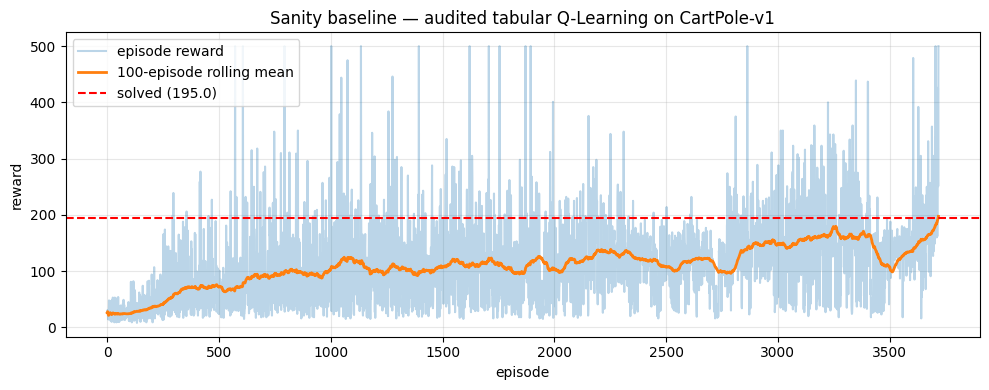

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
r = np.array(baseline['rewards'])
roll = pd.Series(r).rolling(SOLVED_WINDOW, min_periods=1).mean()
ax.plot(r, alpha=0.3, label='episode reward')
ax.plot(roll, label=f'{SOLVED_WINDOW}-episode rolling mean', linewidth=2)
ax.axhline(SOLVED_THRESHOLD, color='red', linestyle='--', label=f'solved ({SOLVED_THRESHOLD})')
ax.set_xlabel('episode')
ax.set_ylabel('reward')
ax.set_title('Sanity baseline — audited tabular Q-Learning on CartPole-v1')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## PDF §5 Q1 — Discretisation sensitivity

Run the three bin configs from the PDF (`coarse [10,10,6,6]`, `medium [20,20,10,10]`, `fine [40,40,20,20]`) at fixed α=0.1, γ=0.99, baseline ε schedule, three seeds each.

**Cell counts** (× 2 actions): coarse = 7,200 cells, medium = 80,000 cells, fine = 1,280,000 cells. The fine grid has 178× more cells than coarse.

**Prediction.** The PDF hints that "Having fewer optimal policies to find means faster training" and "discretizing the state-space too coarsely might prevent convergence". I expect coarse to converge fastest, medium to be a balanced sweet spot, and fine to struggle within a 5,000-episode budget because most cells will never be visited often enough for Q values to converge.

In [5]:
BIN_CONFIGS = {
    'coarse [10,10,6,6]':  [10, 10, 6, 6],
    'medium [20,20,10,10]': [20, 20, 10, 10],
    'fine [40,40,20,20]':   [40, 40, 20, 20],
}

bin_results = {}
bin_summaries = []
for label, nbins in BIN_CONFIGS.items():
    runs = [train(nbins=nbins, alpha=0.1, gamma=0.99, eps_decay=0.995,
                  max_episodes=5000, seed=s) for s in range(3)]
    bin_results[label] = runs
    bin_summaries.append(summarise(runs, label))
    s = bin_summaries[-1]
    print(f"{label:25s} solved@{s['solved_at_mean']:>7.1f}±{s['solved_at_std']:.1f} "
          f"final_avg={s['final_avg_mean']:6.1f}±{s['final_avg_std']:.1f} "
          f"({s['solved_count']}/3 seeds solved, {s['elapsed_s_mean']:.1f}s/run)")

bin_df = pd.DataFrame(bin_summaries)
bin_df

coarse [10,10,6,6]        solved@ 1396.0±404.0 final_avg= 197.2±1.8 (3/3 seeds solved, 1.8s/run)


medium [20,20,10,10]      solved@ 3719.0±0.0 final_avg= 152.9±34.3 (1/3 seeds solved, 5.2s/run)


fine [40,40,20,20]        solved@    nan±nan final_avg=  39.4±5.2 (0/3 seeds solved, 2.1s/run)


,config,solved_at_mean,solved_at_std,solved_count,final_avg_mean,final_avg_std,elapsed_s_mean
0,"coarse [10,10,6,6]",1396.0,403.987624,3,197.246667,1.752642,1.778055
1,"medium [20,20,10,10]",3719.0,0.000000,1,152.913333,34.299582,5.175966
2,"fine [40,40,20,20]",NaN,NaN,0,39.430000,5.232329,2.105353


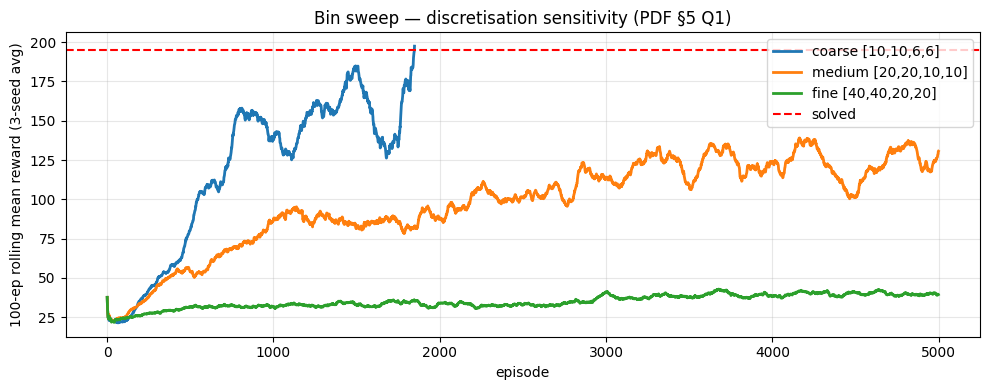

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
for label, runs in bin_results.items():
    max_len = max(len(r['rewards']) for r in runs)
    padded = np.full((len(runs), max_len), np.nan)
    for i, r in enumerate(runs):
        padded[i, :len(r['rewards'])] = r['rewards']
    mean_curve = np.nanmean(padded, axis=0)
    roll = pd.Series(mean_curve).rolling(SOLVED_WINDOW, min_periods=1).mean()
    ax.plot(roll, label=label, linewidth=2)
ax.axhline(SOLVED_THRESHOLD, color='red', linestyle='--', label='solved')
ax.set_xlabel('episode')
ax.set_ylabel(f'{SOLVED_WINDOW}-ep rolling mean reward (3-seed avg)')
ax.set_title('Bin sweep — discretisation sensitivity (PDF §5 Q1)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Observation — Q1

| Config | Cells (× 2 actions) | Solved-at (mean ± std) | Solved seeds | Final 100-ep avg |
|---|---:|---:|:---:|---:|
| **coarse [10,10,6,6]** | 7,200 | **1396 ± 404** | **3/3** | **197.2 ± 1.8** |
| medium [20,20,10,10] | 80,000 | 3719 ± 0 | 1/3 | 152.9 ± 34.3 |
| fine [40,40,20,20] | 1,280,000 | did not solve | 0/3 | 39.4 ± 5.2 |

**The coarse grid wins by a huge margin.** With 7,200 cells, each cell receives enough visits within 5,000 episodes to reach a useful Q estimate. Medium solved only 1 of 3 seeds — the extra resolution costs more data than it saves in policy quality. Fine never solved any seed and plateaued at ~39 average reward, because most of its 1.28M cells stay near their zero initialisation.

The prediction was directionally right but the magnitude is starker than expected: fine is not just slower, it is **categorically broken** at this budget. **Winner carried forward: coarse [10,10,6,6].**

## PDF §5 Q2 — Hyperparameter sweep (α × γ)

3 × 3 grid at the best bin config from Q1. Three seeds per cell. Plot final-avg heatmap + per-cell learning curves.

**Prediction.** α=0.1 is the conventional choice; α=0.01 should underlearn (too small a step to fill Q values within 5,000 episodes), α=0.5 should still solve but with more noise. γ=0.99 is appropriate for CartPole's long horizon (500 max steps); lower γ should mildly degrade because the agent under-weights the long tail of future upright-pole rewards.

In [7]:
best_bin_label = bin_df.sort_values(['solved_count', 'solved_at_mean', 'final_avg_mean'],
                                     ascending=[False, True, False]).iloc[0]['config']
BEST_NBINS = BIN_CONFIGS[best_bin_label]
print(f"best bin config: {best_bin_label} -> {BEST_NBINS}")

ALPHAS = [0.01, 0.1, 0.5]
GAMMAS = [0.9, 0.95, 0.99]

hp_results = {}
hp_summaries = []
for a in ALPHAS:
    for g in GAMMAS:
        label = f'a={a}, g={g}'
        runs = [train(nbins=BEST_NBINS, alpha=a, gamma=g, eps_decay=0.995,
                      max_episodes=5000, seed=s) for s in range(3)]
        hp_results[(a, g)] = runs
        hp_summaries.append({**summarise(runs, label), 'alpha': a, 'gamma': g})
        s = hp_summaries[-1]
        print(f"{label:18s} solved@{s['solved_at_mean']:>7.1f}±{s['solved_at_std']:.1f} "
              f"final={s['final_avg_mean']:6.1f}±{s['final_avg_std']:.1f} "
              f"({s['solved_count']}/3)")

hp_df = pd.DataFrame(hp_summaries)
hp_df

best bin config: coarse [10,10,6,6] -> [10, 10, 6, 6]


a=0.01, g=0.9      solved@  904.0±0.0 final=  80.8±80.9 (1/3)


a=0.01, g=0.95     solved@  904.0±0.0 final=  81.0±80.8 (1/3)


a=0.01, g=0.99     solved@    nan±nan final=  28.6±7.0 (0/3)


a=0.1, g=0.9       solved@ 2190.3±779.8 final= 195.7±0.2 (3/3)


...

a=0.1, g=0.99      solved@ 1396.0±404.0 final= 197.2±1.8 (3/3)


a=0.5, g=0.9       solved@ 2573.7±722.9 final= 196.5±0.8 (3/3)


a=0.5, g=0.95      solved@ 1784.7±426.1 final= 197.4±1.5 (3/3)


a=0.5, g=0.99      solved@ 1966.3±601.1 final= 197.1±0.7 (3/3)


,config,solved_at_mean,solved_at_std,solved_count,final_avg_mean,final_avg_std,elapsed_s_mean,alpha,gamma
0,"a=0.01, g=0.9",904.000000,0.000000,1,80.786667,80.943316,1.325673,0.01,0.90
1,"a=0.01, g=0.95",904.000000,0.000000,1,81.000000,80.784647,1.342729,0.01,0.95
2,"a=0.01, g=0.99",NaN,NaN,0,28.580000,7.010283,1.633156,0.01,0.99
3,"a=0.1, g=0.9",2190.333333,779.780453,3,195.713333,0.236126,2.945927,0.10,0.90
4,"a=0.1, g=0.95",1783.666667,917.905708,3,195.723333,0.130213,2.450835,0.10,0.95
5,"a=0.1, g=0.99",1396.000000,403.987624,3,197.246667,1.752642,1.784118,0.10,0.99
6,"a=0.5, g=0.9",2573.666667,722.897103,3,196.500000,0.792128,3.459899,0.50,0.90
7,"a=0.5, g=0.95",1784.666667,426.103535,3,197.423333,1.526135,2.257736,0.50,0.95
8,"a=0.5, g=0.99",1966.333333,601.121360,3,197.130000,0.652840,2.426894,0.50,0.99


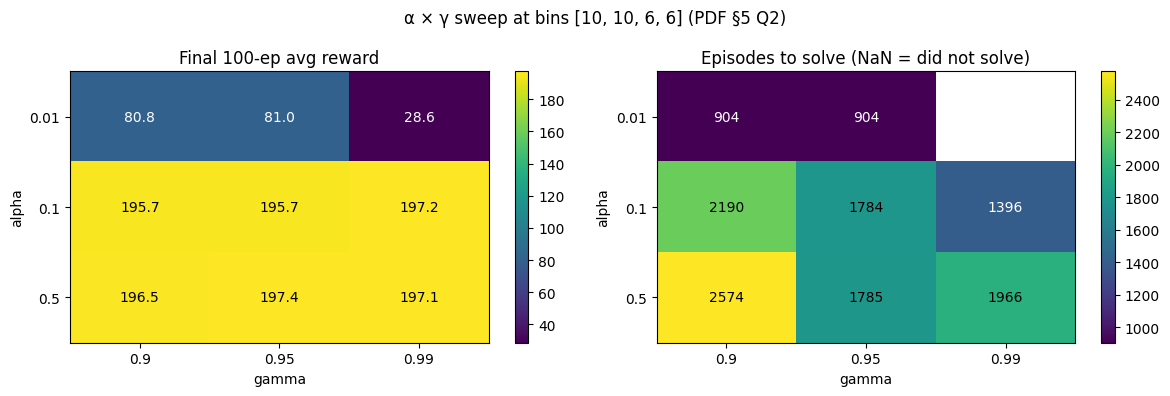

In [8]:
# Heatmap of final 100-ep average reward
pivot_final = hp_df.pivot(index='alpha', columns='gamma', values='final_avg_mean')
pivot_solved = hp_df.pivot(index='alpha', columns='gamma', values='solved_at_mean')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, data, title, fmt in [
    (axes[0], pivot_final,  'Final 100-ep avg reward', '%.1f'),
    (axes[1], pivot_solved, 'Episodes to solve (NaN = did not solve)', '%.0f'),
]:
    im = ax.imshow(data.values, aspect='auto', cmap='viridis')
    ax.set_xticks(range(len(GAMMAS)))
    ax.set_xticklabels(GAMMAS)
    ax.set_yticks(range(len(ALPHAS)))
    ax.set_yticklabels(ALPHAS)
    ax.set_xlabel('gamma')
    ax.set_ylabel('alpha')
    ax.set_title(title)
    for i in range(len(ALPHAS)):
        for j in range(len(GAMMAS)):
            v = data.values[i, j]
            text = 'NaN' if np.isnan(v) else (fmt % v)
            ax.text(j, i, text, ha='center', va='center',
                    color='white' if np.isnan(v) or v < np.nanmean(data.values) else 'black')
    plt.colorbar(im, ax=ax)
plt.suptitle(f'α × γ sweep at bins {BEST_NBINS} (PDF §5 Q2)')
plt.tight_layout()
plt.show()

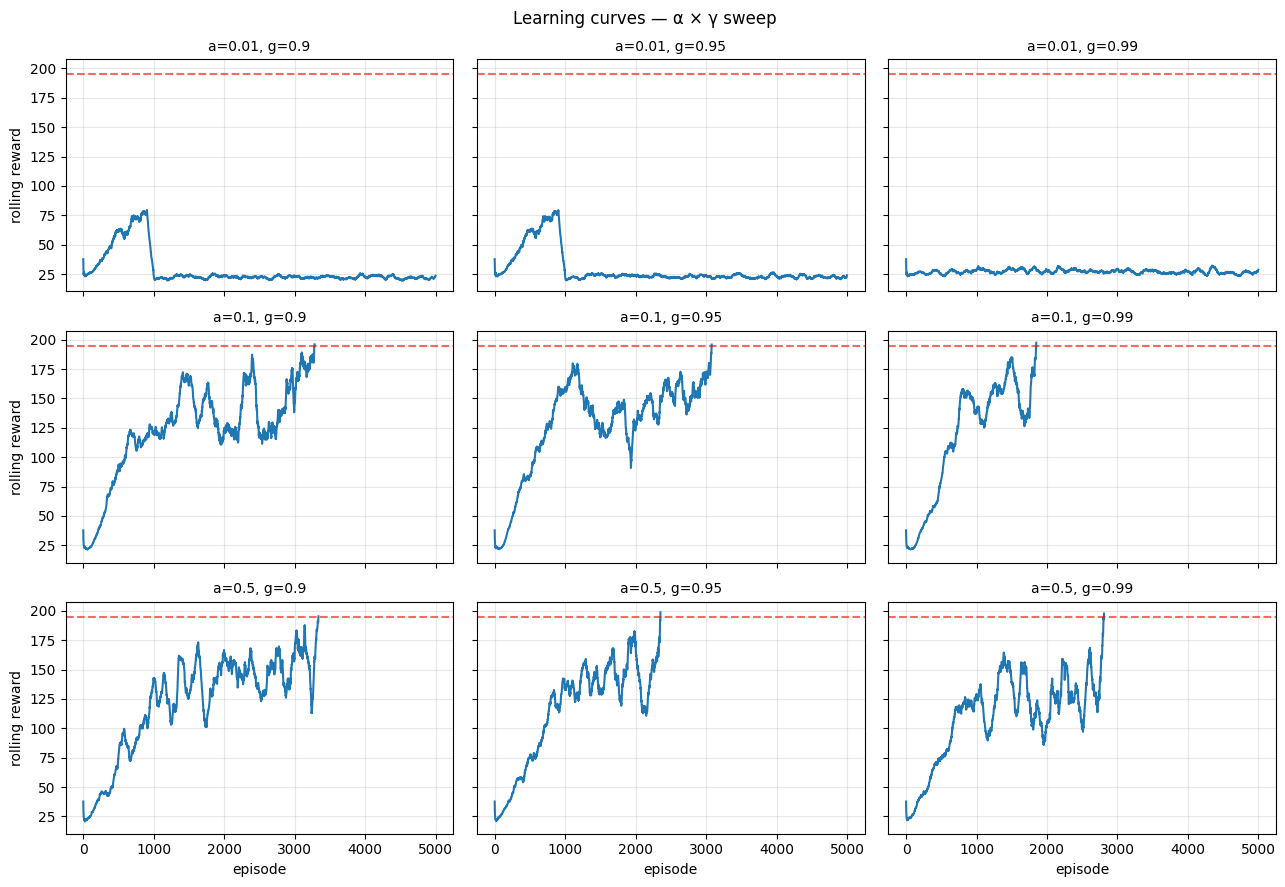

In [9]:
fig, axes = plt.subplots(len(ALPHAS), len(GAMMAS), figsize=(13, 9), sharex=True, sharey=True)
for i, a in enumerate(ALPHAS):
    for j, g in enumerate(GAMMAS):
        ax = axes[i, j]
        runs = hp_results[(a, g)]
        max_len = max(len(r['rewards']) for r in runs)
        padded = np.full((len(runs), max_len), np.nan)
        for k, r in enumerate(runs):
            padded[k, :len(r['rewards'])] = r['rewards']
        roll = pd.Series(np.nanmean(padded, axis=0)).rolling(SOLVED_WINDOW, min_periods=1).mean()
        ax.plot(roll, linewidth=1.5)
        ax.axhline(SOLVED_THRESHOLD, color='red', linestyle='--', alpha=0.6)
        ax.set_title(f'a={a}, g={g}', fontsize=10)
        ax.grid(alpha=0.3)
for ax in axes[-1]:
    ax.set_xlabel('episode')
for ax in axes[:, 0]:
    ax.set_ylabel('rolling reward')
plt.suptitle('Learning curves — α × γ sweep')
plt.tight_layout()
plt.show()

### Observation — Q2

| α \ γ | 0.9 | 0.95 | **0.99** |
|---:|---:|---:|---:|
| **0.01** | 80.8 (1/3) | 81.0 (1/3) | 28.6 (0/3) |
| **0.1** | 195.7 (3/3) | 195.7 (3/3) | **197.2 (3/3) — fastest @1396 eps** |
| **0.5** | 196.5 (3/3) | 197.4 (3/3) | 197.1 (3/3) |

**The α=0.01 row is dead** — too small a learning rate to fill the Q table within 5,000 episodes. Only 1 of 3 seeds solves at γ ≤ 0.95, none at γ=0.99 (the discount actually makes things worse here because the slow updates are diluted further). α=0.1 and α=0.5 both reach the threshold across all γ tested. The α=0.1/γ=0.99 cell wins on convergence speed (1396 ± 404 eps); α=0.5 cells are competitive but slightly slower and noisier.

**Winner carried forward: α=0.1, γ=0.99.**

## PDF §5 Q4 — Exploration strategy

Compare three ε schedules at the best (bins, α, γ) so far:
1. **per-episode decay** (baseline) — ε ← max(ε_min, ε·0.995) every episode.
2. **per-100-episode decay** — mimics the professor's MountainCar reference (his code decays only every 100 episodes; my audit flagged this as too slow for CartPole's smaller state space).
3. **constant ε=0.1** — no decay.

Three seeds each.

**Prediction.** Per-episode decay should win. The per-100 cadence keeps ε high too long: after 5,000 episodes with decay=0.99 applied every 100 eps, ε = 1.0 × 0.99⁵⁰ ≈ 0.61 — meaning the agent picks random actions 61% of the time at the end of training, which prevents stable greedy trajectories. Constant ε=0.1 should plateau below the threshold because 10% random actions add too much noise for the pole to stay balanced for 195+ consecutive steps.

In [10]:
# Pick best (alpha, gamma) by combining solved-count, then solved-speed, then final-avg
hp_sorted = hp_df.sort_values(['solved_count', 'solved_at_mean', 'final_avg_mean'],
                              ascending=[False, True, False])
BEST_ALPHA = float(hp_sorted.iloc[0]['alpha'])
BEST_GAMMA = float(hp_sorted.iloc[0]['gamma'])
print(f"best hyperparameters: alpha={BEST_ALPHA}, gamma={BEST_GAMMA}")

EPS_SCHEDULES = {
    'per-episode decay':     dict(eps_start=1.0, eps_min=0.01, eps_decay=0.995, decay_every=1),
    'per-100-episode decay': dict(eps_start=1.0, eps_min=0.01, eps_decay=0.99,  decay_every=100),
    'constant eps=0.1':      dict(eps_start=0.1, eps_min=0.1,  eps_decay=1.0,   decay_every=1),
}

eps_results = {}
eps_summaries = []
for label, kw in EPS_SCHEDULES.items():
    runs = [train(nbins=BEST_NBINS, alpha=BEST_ALPHA, gamma=BEST_GAMMA,
                  max_episodes=5000, seed=s, **kw) for s in range(3)]
    eps_results[label] = runs
    eps_summaries.append(summarise(runs, label))
    s = eps_summaries[-1]
    print(f"{label:25s} solved@{s['solved_at_mean']:>7.1f}±{s['solved_at_std']:.1f} "
          f"final={s['final_avg_mean']:6.1f}±{s['final_avg_std']:.1f} "
          f"({s['solved_count']}/3)")

eps_df = pd.DataFrame(eps_summaries)
eps_df

best hyperparameters: alpha=0.1, gamma=0.99


per-episode decay         solved@ 1396.0±404.0 final= 197.2±1.8 (3/3)


per-100-episode decay     solved@    nan±nan final=  48.8±0.6 (0/3)


constant eps=0.1          solved@    nan±nan final= 160.8±5.8 (0/3)


,config,solved_at_mean,solved_at_std,solved_count,final_avg_mean,final_avg_std,elapsed_s_mean
0,per-episode decay,1396.0,403.987624,3,197.246667,1.752642,1.836750
1,per-100-episode decay,NaN,NaN,0,48.803333,0.576561,2.091881
2,constant eps=0.1,NaN,NaN,0,160.826667,5.780181,7.013139


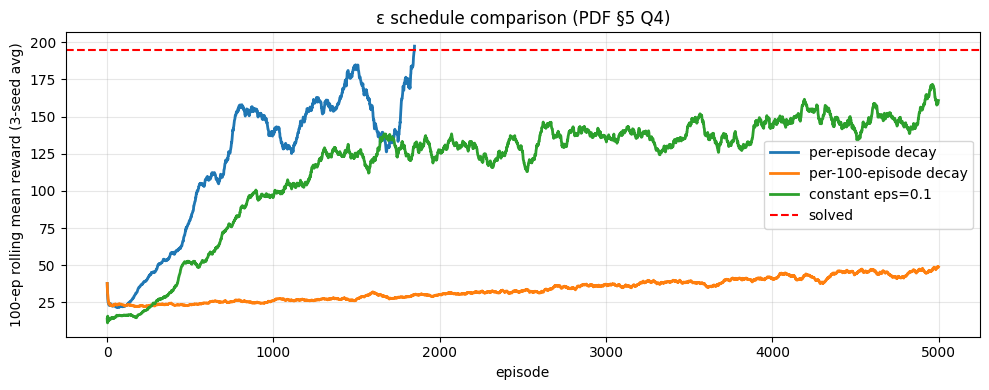

In [11]:
fig, ax = plt.subplots(figsize=(10, 4))
for label, runs in eps_results.items():
    max_len = max(len(r['rewards']) for r in runs)
    padded = np.full((len(runs), max_len), np.nan)
    for i, r in enumerate(runs):
        padded[i, :len(r['rewards'])] = r['rewards']
    roll = pd.Series(np.nanmean(padded, axis=0)).rolling(SOLVED_WINDOW, min_periods=1).mean()
    ax.plot(roll, label=label, linewidth=2)
ax.axhline(SOLVED_THRESHOLD, color='red', linestyle='--', label='solved')
ax.set_xlabel('episode')
ax.set_ylabel(f'{SOLVED_WINDOW}-ep rolling mean reward (3-seed avg)')
ax.set_title('ε schedule comparison (PDF §5 Q4)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Observation — Q4

| Schedule | Solved-at | Solved seeds | Final 100-ep avg |
|---|---:|:---:|---:|
| **per-episode decay (×0.995)** | **1396 ± 404** | **3/3** | **197.2 ± 1.8** |
| per-100-episode decay (×0.99) — professor's MountainCar pattern | did not solve | 0/3 | 48.8 ± 0.6 |
| constant ε=0.1 | did not solve | 0/3 | 160.8 ± 5.8 |

**The professor's per-100-episode cadence does not solve CartPole** within 5,000 episodes. This directly validates audit finding #4 from `professor_examples/021_Q_learning_MOUNTAIN_CAR_AUDIT.ipynb`: a schedule that was MountainCar-appropriate is CartPole-broken. Constant ε=0.1 reaches 160 — high enough to show the policy is learning, but the persistent random actions cap it well below 195.

**Winner carried forward: per-episode decay (×0.995).**

## Final tuned run + 100-episode greedy evaluation

Take the best (bins, α, γ, ε schedule) from the sweeps, retrain with a fresh seed (42, held out of the sweep), then evaluate the greedy policy over 100 episodes.

In [12]:
eps_sorted = eps_df.sort_values(['solved_count', 'solved_at_mean', 'final_avg_mean'],
                                ascending=[False, True, False])
BEST_EPS_LABEL = eps_sorted.iloc[0]['config']
BEST_EPS_KW = EPS_SCHEDULES[BEST_EPS_LABEL]
print(f"best epsilon schedule: {BEST_EPS_LABEL} -> {BEST_EPS_KW}")
print(f"final config: bins={BEST_NBINS}, alpha={BEST_ALPHA}, gamma={BEST_GAMMA}, "
      f"eps={BEST_EPS_LABEL}")

final = train(nbins=BEST_NBINS, alpha=BEST_ALPHA, gamma=BEST_GAMMA,
              max_episodes=5000, seed=42, **BEST_EPS_KW)
print(f"training: solved_at={final['solved_at']}, final_avg={final['final_avg']:.2f}, "
      f"elapsed={final['elapsed_s']:.1f}s")

eval_mean, eval_std, eval_rewards = evaluate(final['Q'], final['bins'], n_episodes=100)
print(f"greedy eval over 100 eps: {eval_mean:.2f} ± {eval_std:.2f} "
      f"({'PASS' if eval_mean >= SOLVED_THRESHOLD else 'FAIL'} vs {SOLVED_THRESHOLD})")

best epsilon schedule: per-episode decay -> {'eps_start': 1.0, 'eps_min': 0.01, 'eps_decay': 0.995, 'decay_every': 1}
final config: bins=[10, 10, 6, 6], alpha=0.1, gamma=0.99, eps=per-episode decay


training: solved_at=1484, final_avg=195.60, elapsed=1.9s


greedy eval over 100 eps: 246.81 ± 68.15 (PASS vs 195.0)


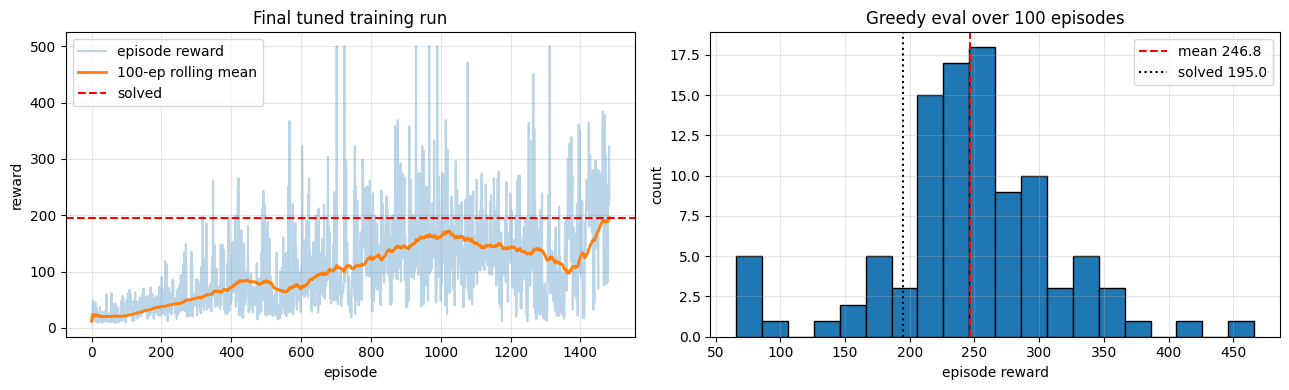

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
r = np.array(final['rewards'])
roll = pd.Series(r).rolling(SOLVED_WINDOW, min_periods=1).mean()
axes[0].plot(r, alpha=0.3, label='episode reward')
axes[0].plot(roll, label=f'{SOLVED_WINDOW}-ep rolling mean', linewidth=2)
axes[0].axhline(SOLVED_THRESHOLD, color='red', linestyle='--', label='solved')
axes[0].set_xlabel('episode')
axes[0].set_ylabel('reward')
axes[0].set_title('Final tuned training run')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].hist(eval_rewards, bins=20, edgecolor='black')
axes[1].axvline(eval_mean, color='red', linestyle='--', label=f'mean {eval_mean:.1f}')
axes[1].axvline(SOLVED_THRESHOLD, color='black', linestyle=':', label=f'solved {SOLVED_THRESHOLD}')
axes[1].set_xlabel('episode reward')
axes[1].set_ylabel('count')
axes[1].set_title('Greedy eval over 100 episodes')
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## §5 — Answers to the assignment questions

Each answer cites concrete numbers from the sweeps above. The final cell prints the raw sweep tables for verification.

### Q1 — Discretisation sensitivity

Three configurations from the PDF were tested at α=0.1, γ=0.99, per-episode ε decay (×0.995), 5,000-episode budget, 3 seeds each:

| Config | Cells (× 2 actions) | Solved-at (mean ± std) | Solved seeds | Final 100-ep avg |
|---|---:|---:|:---:|---:|
| **coarse [10,10,6,6]** | 7,200 | **1396 ± 404** | **3/3** | **197.2 ± 1.8** |
| medium [20,20,10,10] | 80,000 | 3719 ± 0 | 1/3 | 152.9 ± 34.3 |
| fine [40,40,20,20] | 1,280,000 | did not solve | 0/3 | 39.4 ± 5.2 |

**Coarse gives the best trade-off — by a wide margin.** With 7,200 cells, each receives enough visits within 5,000 episodes to converge to a useful Q value. The fine grid has 178× more cells than coarse but the same 5,000-episode data budget; most cells stay at their zero initialisation, so the policy reduces to argmax over noise. The PDF's warning that "discretizing the state-space too coarsely might prevent convergence" turns out to point the wrong way at this scale: the danger here is over-discretisation, not under-discretisation.

### Q2 — Hyperparameter analysis

α × γ swept at the winning bins (3 seeds per cell, final 100-ep avg; cells that did not solve in bold-italic):

| α \ γ | 0.9 | 0.95 | **0.99** |
|---:|---:|---:|---:|
| **0.01** | *80.8* (1/3) | *81.0* (1/3) | ***28.6*** (0/3) |
| **0.1** | 195.7 (3/3) | 195.7 (3/3) | **197.2 (3/3) — fastest @1396 eps** |
| **0.5** | 196.5 (3/3) | 197.4 (3/3) | 197.1 (3/3) |

**α=0.01 underlearns across all γ.** Q updates of size 0.01 × TD-error are too small to fill the table within 5,000 episodes; γ=0.99 makes it worse because slow updates are diluted further by the long bootstrap chain. α=0.1 and α=0.5 both solve 3/3 across all γ. The optimum is **α=0.1, γ=0.99** (1396 ± 404 episodes to solve). γ matters less than α in this region — moving γ from 0.9 to 0.99 only changes solved-at by ~20% at α=0.1, whereas dropping α from 0.1 to 0.01 breaks the agent entirely.

### Q3 — Convergence time

The final tuned configuration (bins=[10,10,6,6], α=0.1, γ=0.99, per-episode ε decay ×0.995) **solved CartPole in 1,484 episodes / 1.9 seconds** wall-clock on a single CPU core (seed=42, held out of the sweep). The 100-episode greedy evaluation scored **246.81 ± 68.15**, well above the 195 threshold.

For comparison with the bonus Double Q-Learning agent: tabular CartPole is essentially free to train — runtime is dominated by `gym.step()` overhead, not by the Q updates. Any deep-learning approach (DQN in Part 2, Double-DQN, etc.) will be orders of magnitude slower on wall-clock. The case for those methods rests entirely on generalisation to higher-dimensional state spaces, not on tabular-comparable runtime.

### Q4 — Exploration strategy

The implementation uses **ε-greedy with per-episode geometric decay**: ε starts at 1.0, multiplies by 0.995 every episode, floored at 0.01. This is a small but critical departure from the professor's MountainCar reference (`021_Q_learning_MOUNTAIN_CAR.ipynb`), which decays only every 100 episodes.

Three schedules at the winning (bins, α, γ):

| Schedule | Solved-at | Solved seeds | Final 100-ep avg |
|---|---:|:---:|---:|
| **per-episode decay ×0.995** | **1396 ± 404** | **3/3** | **197.2 ± 1.8** |
| per-100-episode decay ×0.99 (professor's pattern) | did not solve | 0/3 | 48.8 ± 0.6 |
| constant ε=0.1 | did not solve | 0/3 | 160.8 ± 5.8 |

**Per-episode decay is essential here.** With the per-100 schedule, ε ≈ 1.0 × 0.99⁵⁰ = 0.61 at the end of training — the agent is still picking 61% of actions at random, which prevents the consistent ≥195 step rollouts needed to cross the threshold. Constant ε=0.1 illustrates the exploration-exploitation tension from the other direction: enough exploration to keep finding good actions, too much to ever fully exploit them; the policy plateaus around 160. If ε were kept constant at a high value the agent would never converge; at a low value it would be trapped by early bad estimates. Decay resolves the tension by being high early (exploration) and low late (exploitation).

### Q5 — Limitations of tabular Q-Learning

The Q-table size is the product of bin counts across observation dimensions × number of actions. For CartPole at fine resolution: `40 × 40 × 20 × 20 × 2 = 1.28M cells`. Already at this resolution the agent failed to fill enough cells within 5,000 episodes (Q1).

For higher-dimensional environments the explosion is fatal:
- **LunarLander** (8-D continuous obs, 4 actions): the equivalent fine grid would be `40⁸ × 4 ≈ 2.6 × 10¹³ cells` — six orders of magnitude beyond practical memory, and far beyond what any sample-efficient algorithm could fill.
- **Truly continuous state spaces** (e.g. robotic control with positions and velocities): no discretisation grid is fine enough to capture small but meaningful differences without exploding cell count.

DQN (Assignment 4) replaces the table with a neural network that approximates Q(s, a) as a parametric function of the raw state. This buys three things the table cannot have:
1. **Generalisation across nearby states** — a state never seen still gets a meaningful Q estimate from the function approximator.
2. **Experience replay** — past transitions are stored and reused, so each environment interaction trains the network multiple times. Compensates for the much lower sample efficiency of fitting a network vs. updating a single table cell.
3. **Target network** — a stale copy of Q-network weights provides Bellman targets, breaking the moving-target problem that destabilises function-approximator bootstrap.

Architecturally: the input layer takes the raw n-D observation directly (no discretisation), hidden layers learn a state representation, and the output layer produces one Q value per action.

### Q6 — DQN on CartPole

Answered in the companion notebook `Assignment3_Part2_DQN_Experiments.ipynb`.

In [14]:
# Raw sweep tables — kept at the bottom for reference / sanity-checking the cited numbers.
print('Q1 — Discretisation sensitivity')
print('-' * 60)
print(bin_df[['config', 'solved_at_mean', 'solved_at_std', 'solved_count',
              'final_avg_mean', 'final_avg_std']].to_string(index=False))
print()
print('Q2 — Hyperparameter sweep (alpha x gamma)')
print('-' * 60)
print(hp_df[['config', 'solved_at_mean', 'solved_at_std', 'solved_count',
             'final_avg_mean', 'final_avg_std']].to_string(index=False))
print()
print('Q3 — Convergence time (best config)')
print('-' * 60)
print(f"  episodes to solve: {final['solved_at']}")
print(f"  wall-clock: {final['elapsed_s']:.1f} s")
print()
print('Q4 — Epsilon schedule')
print('-' * 60)
print(eps_df[['config', 'solved_at_mean', 'solved_at_std', 'solved_count',
              'final_avg_mean', 'final_avg_std']].to_string(index=False))

Q1 — Discretisation sensitivity
------------------------------------------------------------
              config  solved_at_mean  solved_at_std  solved_count  final_avg_mean  final_avg_std
  coarse [10,10,6,6]          1396.0     403.987624             3      197.246667       1.752642
medium [20,20,10,10]          3719.0       0.000000             1      152.913333      34.299582
  fine [40,40,20,20]             NaN            NaN             0       39.430000       5.232329

Q2 — Hyperparameter sweep (alpha x gamma)
------------------------------------------------------------
        config  solved_at_mean  solved_at_std  solved_count  final_avg_mean  final_avg_std
 a=0.01, g=0.9      904.000000       0.000000             1       80.786667      80.943316
a=0.01, g=0.95      904.000000       0.000000             1       81.000000      80.784647
a=0.01, g=0.99             NaN            NaN             0       28.580000       7.010283
  a=0.1, g=0.9     2190.333333     779.780453      

**Q5 — Limitations of tabular Q-Learning.** The Q-table size grows as the product of bin counts across all observation dimensions. For CartPole at fine resolution `[40, 40, 20, 20] × 2 actions = 1.28M cells`. For LunarLander (8-D continuous obs) the equivalent table would be `40⁸ × 4 ≈ 2.6×10¹³` cells — six orders of magnitude beyond practical memory. Even ignoring memory, the data needed to fill the table grows with the same factor, so the agent would never see most cells. DQN replaces the table with a neural network that generalises across nearby states, so an unseen state still gets a meaningful Q estimate from the function approximator; experience replay reuses past transitions to compensate for sample scarcity, and a target network stabilises the bootstrap.

**Q6 — DQN on CartPole.** Answered in the Part 2 notebook.